# 📊 Data Mining & Tech Salary Regression Analysis

This notebook performs end-to-end Data Mining, Exploratory Data Analysis (EDA), Feature Engineering, and Machine Learning modeling on tech compensation data:
1. **Data Ingestion & Cleaning**: Standardizing job titles, locations, compensation ranges, and seniority levels.
2. **Feature Engineering**: Deriving experience benchmarks, skill density counts, and company tiers.
3. **Exploratory Data Analysis (EDA)**: Visualizing compensation distributions, experience trends, and geographic variance.
4. **Data Mining Insights**: Identifying high-paying technical skills and compensation drivers.
5. **Machine Learning Modeling**: Training and evaluating Linear Regression and Random Forest Regressors.


In [1]:
# 1. Import Core Libraries
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Configure visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
print('Libraries imported successfully.')


Libraries imported successfully.


In [2]:
# 2. Load Dataset
dataset_file = 'Salary_Dataset_DataScienceLovers.csv'
df = pd.read_csv(dataset_file)
print(f'Successfully loaded: {dataset_file}')
print(f'Initial Shape: {df.shape}')
df.head()


Successfully loaded: Salary_Dataset_DataScienceLovers.csv
Initial Shape: (22770, 8)


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android


In [3]:
# 3. Data Cleaning & Normalization
# Standardize column names
df.columns = df.columns.str.lower().str.strip()

# Convert annual salary from INR to LPA (Lakhs Per Annum)
if 'salary' in df.columns:
    df['salary_lpa'] = df['salary'] / 100000.0

# Extract experience from Job Title & Employment Status
def estimate_experience(row):
    title = str(row.get('job title', '')).lower()
    status = str(row.get('employment status', '')).lower()
    
    if 'intern' in status or 'intern' in title or 'trainee' in title:
        return 0.5
    if any(w in title for w in ['junior', 'jr', 'entry', 'associate', 'sde i', 'sde 1']):
        return 1.5
    if any(w in title for w in ['senior', 'sr', 'sde iii', 'sde 3']):
        return 6.0
    if any(w in title for w in ['lead', 'staff']):
        return 8.5
    if any(w in title for w in ['principal', 'architect', 'manager', 'director', 'head']):
        return 12.0
    if any(w in title for w in ['sde ii', 'sde 2', 'developer ii']):
        return 4.0
    return 3.0

df['experience'] = df.apply(estimate_experience, axis=1)

# Clean skills and extract skill count
skills_col = 'job roles' if 'job roles' in df.columns else 'skills'
df['skills'] = df[skills_col].fillna('General').astype(str)
df['skill_count'] = df['skills'].apply(lambda x: len(re.split(r'[,\s]+', str(x).strip()))).clip(1, 20)

# Outlier filtering (1.0 to 60.0 LPA)
df = df.dropna(subset=['salary_lpa', 'experience'])
df = df[(df['salary_lpa'] >= 1.0) & (df['salary_lpa'] <= 60.0)]
df = df[(df['experience'] >= 0.0) & (df['experience'] <= 30.0)]

print(f'Cleaned dataset shape: {df.shape}')
print(df[['job title', 'location', 'experience', 'salary_lpa', 'skill_count']].describe())


Cleaned dataset shape: (22370, 12)
         experience    salary_lpa  skill_count
count  22370.000000  22370.000000      22370.0
mean       3.132521      6.920728          1.0
std        1.453142      5.979613          0.0
min        0.500000      1.000000          1.0
25%        3.000000      3.000000          1.0
50%        3.000000      5.000000          1.0
75%        3.000000      9.000000          1.0
max       12.000000     59.000000          1.0


/var/folders/_6/1m3sr4td30148nvmb70jwp6w0000gn/T/ipykernel_38040/989013082.py:10: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


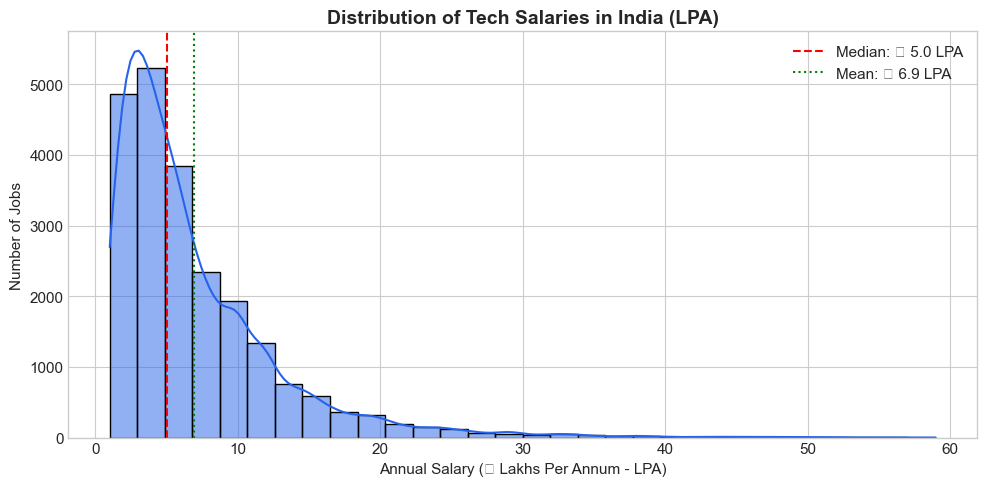

In [4]:
# 4. EDA: Overall Salary Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['salary_lpa'], bins=30, kde=True, color='#2563eb')
plt.title('Distribution of Tech Salaries in India (LPA)', fontsize=14, fontweight='bold')
plt.xlabel('Annual Salary (₹ Lakhs Per Annum - LPA)')
plt.ylabel('Number of Jobs')
plt.axvline(df['salary_lpa'].median(), color='red', linestyle='--', label=f'Median: ₹ {df["salary_lpa"].median():.1f} LPA')
plt.axvline(df['salary_lpa'].mean(), color='green', linestyle=':', label=f'Mean: ₹ {df["salary_lpa"].mean():.1f} LPA')
plt.legend()
plt.tight_layout()
plt.show()


/var/folders/_6/1m3sr4td30148nvmb70jwp6w0000gn/T/ipykernel_38040/3073448924.py:7: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


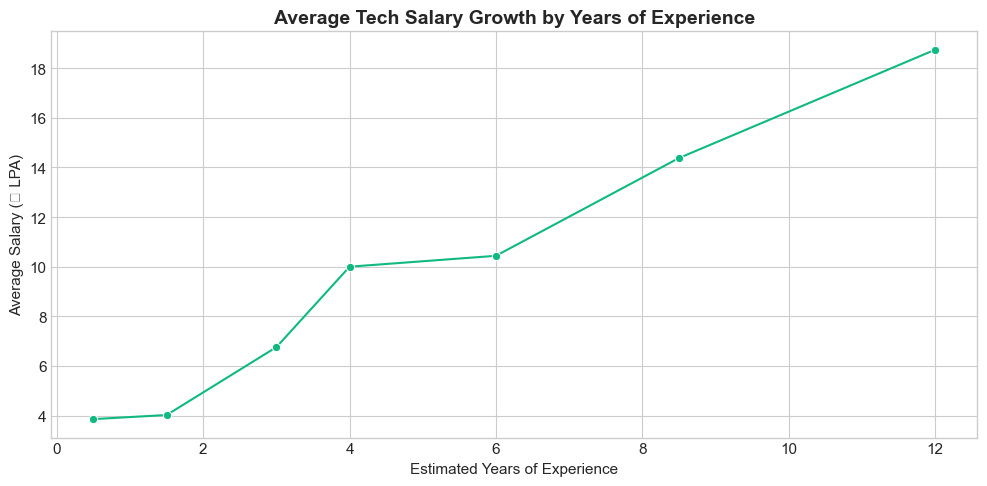

In [5]:
# 5. EDA: Salary vs. Experience
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='experience', y='salary_lpa', marker='o', color='#10b981', errorbar=None)
plt.title('Average Tech Salary Growth by Years of Experience', fontsize=14, fontweight='bold')
plt.xlabel('Estimated Years of Experience')
plt.ylabel('Average Salary (₹ LPA)')
plt.tight_layout()
plt.show()


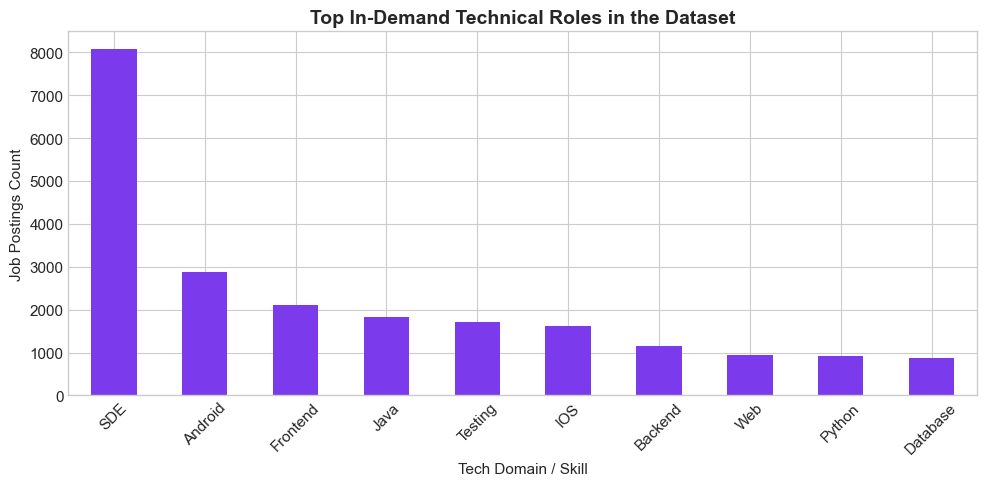

In [6]:
# 6. Data Mining: Top Technical Roles & Domains by Median Salary
top_roles = df['skills'].str.split(',').explode().str.strip().value_counts().head(10)

plt.figure(figsize=(10, 5))
top_roles.plot(kind='bar', color='#7c3aed')
plt.title('Top In-Demand Technical Roles in the Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Tech Domain / Skill')
plt.ylabel('Job Postings Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


/var/folders/_6/1m3sr4td30148nvmb70jwp6w0000gn/T/ipykernel_38040/1940423195.py:9: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


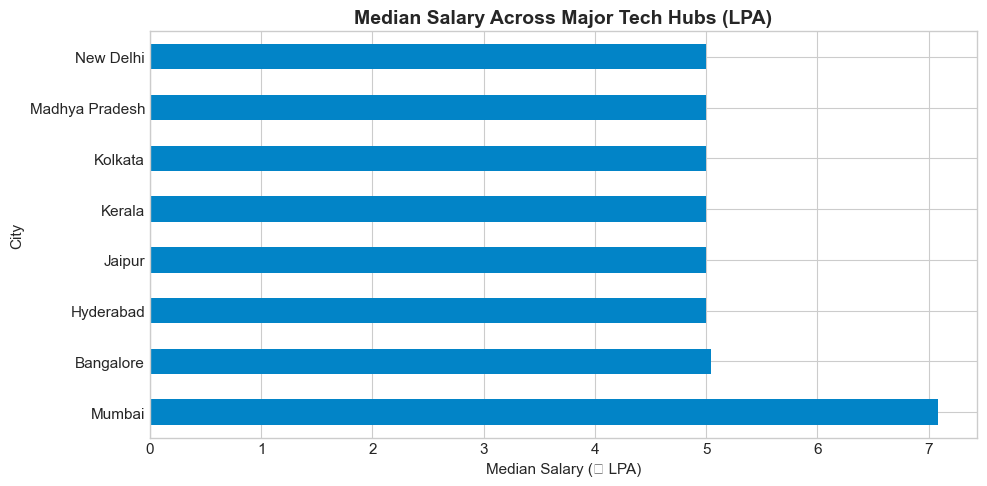

In [7]:
# 7. Geographic Comparison: Median Salary by Major Tech Cities
city_salaries = df.groupby('location')['salary_lpa'].median().sort_values(ascending=False).head(8)

plt.figure(figsize=(10, 5))
city_salaries.plot(kind='barh', color='#0284c7')
plt.title('Median Salary Across Major Tech Hubs (LPA)', fontsize=14, fontweight='bold')
plt.xlabel('Median Salary (₹ LPA)')
plt.ylabel('City')
plt.tight_layout()
plt.show()


In [8]:
# 8. Machine Learning Model Training (Linear Regression & Random Forest)
# Categorical encoding for model features
df['loc_code'] = df['location'].astype('category').cat.codes
df['role_code'] = df['skills'].astype('category').cat.codes

features = ['experience', 'skill_count', 'loc_code', 'role_code']
X = df[features]
y = df['salary_lpa']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression Baseline
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print(f'Linear Regression MAE: {mean_absolute_error(y_test, lr_pred):.2f} LPA | R2: {r2_score(y_test, lr_pred)*100:.2f}%')

# Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print(f'Random Forest Regressor MAE: {mean_absolute_error(y_test, rf_pred):.2f} LPA | R2: {r2_score(y_test, rf_pred)*100:.2f}%')


Linear Regression MAE: 4.00 LPA | R2: 8.54%


Random Forest Regressor MAE: 3.72 LPA | R2: 16.29%


In [9]:
# 9. Sample Salary Prediction
# Example candidate: 4 years experience, 4 skills, Bangalore location, SDE role
sample_exp = 4
sample_skills = 4
sample_loc = df[df["location"].str.lower() == "bangalore"]["loc_code"].iloc[0]
sample_role = df[df["skills"].str.lower().str.contains("sde")]["role_code"].iloc[0]

sample_input = [[sample_exp, sample_skills, sample_loc, sample_role]]
predicted_salary = rf.predict(sample_input)[0]

print(f'Sample Candidate Profile: {sample_exp} yrs experience, SDE in Bangalore')
print(f'Predicted Market Salary: ₹ {predicted_salary:.2f} LPA')
print(f'Estimated Range: ₹ {predicted_salary*0.88:.2f} - {predicted_salary*1.12:.2f} LPA')


Sample Candidate Profile: 4 yrs experience, SDE in Bangalore
Predicted Market Salary: ₹ 10.81 LPA
Estimated Range: ₹ 9.52 - 12.11 LPA


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
